# XGBoost Zone AC Demand Forecasting

This notebook presents the completed XGBoost results for the four feature configurations (M1–M4). The models use the same train/validation/test split and target as the LightGBM workflow.

**Important:** The result cells below are pre-populated from the completed run, so the notebook can be opened and read without rerunning the expensive tuning process. The optional rerun cell is provided for reproducibility.

## 1. Setup and output locations

The default configuration is CPU-based and suitable for an Apple Silicon MacBook Air. A CUDA-enabled Colab environment can be selected by changing `DEVICE` to `cuda`.

In [8]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name != '4-XGBoost':
    ROOT = next(p for p in [ROOT, *ROOT.parents] if p.name == '4-XGBoost')
DATA_DIR = ROOT.parent / 'cleaned_data'
OUTPUT_DIR = ROOT / 'outputs'
print('Project folder:', ROOT)
print('Data folder:', DATA_DIR)
print('Results folder:', OUTPUT_DIR)

Project folder: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/4-XGBoost
Data folder: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/cleaned_data
Results folder: /Users/wzc/Desktop/SMU/Y3T1/IS4001 Smart Building Analytics/project/git/is4001/Qn_B/4-XGBoost/outputs


## 2. Run configuration

The completed result run used 12 deterministic tuning trials per model, four CPU workers, and 3,000 held-out test rows for each SHAP explanation. To rerun the model, install `requirements.txt` and execute the following cell.

In [9]:
# Optional rerun: uncomment only when you want to retrain all four models.
# sys.path.insert(0, str(ROOT))
# from xgboost_forecaster import Config, run
# config = Config(data_dir=DATA_DIR, output_dir=OUTPUT_DIR, device='cpu',
#                 n_jobs=4, tuning_trials=12, shap_sample=3000)
# run(config)

## 3. Dataset and feature configurations

In [10]:
data = pd.read_parquet(DATA_DIR / 'question_b_model_data.parquet')
dictionary = pd.read_csv(DATA_DIR / 'question_b_feature_dictionary.csv')
feature_sets = {m: dictionary.loc[dictionary[m].eq('Yes'), 'column'].tolist() for m in ['M1','M2','M3','M4']}
print(f'Rows: {len(data):,}')
print(f'Columns: {data.shape[1]}')
print('Split counts:')
display(data['split'].value_counts().rename_axis('split').to_frame('rows'))
print('Feature sets used for training:')
display(pd.DataFrame({m: pd.Series(v) for m, v in feature_sets.items()}))

Rows: 209,119
Columns: 35
Split counts:


,rows
split,
train,111779
test,50567
validation,46773


Feature sets used for training:


,M1,M2,M3,M4
0,floor,floor,floor,floor
1,zone_code,zone_code,zone_code,zone_code
2,hour,hour,hour,hour
3,weekday,weekday,weekday,weekday
4,month,month,month,month
5,is_weekend,is_weekend,is_weekend,is_weekend
6,is_holiday,is_holiday,is_holiday,is_holiday
7,ac_load_kw_yesterday,ac_load_kw_yesterday,ac_load_kw_yesterday,ac_load_kw_yesterday
8,ac_load_kw_2_days_ago,ac_load_kw_2_days_ago,ac_load_kw_2_days_ago,ac_load_kw_2_days_ago
9,ac_load_kw_last_week,ac_load_kw_last_week,ac_load_kw_last_week,ac_load_kw_last_week


## 4. Hyperparameter tuning results

The best trial for each model is selected by lowest validation RMSE. The validation data is used only for tuning; the held-out test period is not used for parameter selection.

In [11]:
tuning = pd.read_csv(OUTPUT_DIR / 'tuning_results.csv')
best = tuning.loc[tuning.groupby('model')['validation_rmse'].idxmin()].sort_values('model')
cols = ['model','trial','best_iteration','max_depth','learning_rate','min_child_weight','subsample','colsample_bytree','reg_lambda','reg_alpha','validation_rmse','validation_wape']
display(best[cols].reset_index(drop=True))

,model,trial,best_iteration,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,validation_rmse,validation_wape
0,M1,7,273,8,0.05,1,1.0,0.8,20.0,1.0,2.675384,0.201480
1,M2,7,539,8,0.05,1,1.0,0.8,20.0,1.0,2.623105,0.206649
2,M3,7,683,8,0.05,1,1.0,0.8,20.0,1.0,2.564684,0.210132
3,M4,1,968,4,0.08,5,0.8,0.8,20.0,0.0,2.662131,0.225976


## 5. Main held-out test results

The primary comparison is the test-period performance. WAPE is shown as a percentage; lower values are better. `CV(RMSE)`, NMBE, and WAPE are calculated from the same actual/predicted rows.

In [12]:
metrics = pd.read_csv(OUTPUT_DIR / 'test_metrics.csv')
primary = metrics[(metrics['slice'].isin(['all_hours','operating_hours'])) & metrics['dimension'].isna()].copy()
primary['slice'] = primary['slice'].str.replace('_', ' ').str.title()
display(primary[['model','slice','n','mae','rmse','cv_rmse','nmbe','wape']].round(4))

,model,slice,n,mae,rmse,cv_rmse,nmbe,wape
0,M1,All Hours,50567.0,0.9002,2.7192,0.6270,0.0183,0.2076
1,M1,Operating Hours,14072.0,1.5839,2.6379,0.1916,0.0146,0.1150
36,M2,All Hours,50567.0,1.1465,2.9505,0.6804,0.1072,0.2644
37,M2,Operating Hours,14072.0,1.9799,3.2132,0.2334,0.0773,0.1438
72,M3,All Hours,50567.0,0.9561,2.8202,0.6503,-0.0112,0.2205
73,M3,Operating Hours,14072.0,1.6862,2.7674,0.2010,-0.0212,0.1225
108,M4,All Hours,50567.0,1.2462,2.9911,0.6897,0.0823,0.2874
109,M4,Operating Hours,14072.0,2.1279,3.3016,0.2398,0.0362,0.1545


### Interpretation

Use the **operating-hours WAPE** row when comparing against the supplied baselines (B1 = 16.9%, B3 = 18.1%, B2 = 19.5%). In this run, M1 is the strongest XGBoost configuration on the common scored operating-hour rows; adding indoor/weather variables did not improve the score for this particular XGBoost tuning run.

## 6. Baseline comparison on common scored rows

All models are scored on the same baseline rows where `scored == 1`. This is the fair comparison table for the dashboard/baseline analysis.

In [13]:
common = pd.read_csv(OUTPUT_DIR / 'common_scored_metrics.csv')
display(common[['model','slice','n','mae','rmse','cv_rmse','nmbe','wape']].round(4))

,model,slice,n,mae,rmse,cv_rmse,nmbe,wape
0,M1,all_hours,46064.0,0.8464,2.6289,0.6217,0.0220,0.2002
1,M1,operating_hours,12602.0,1.4995,2.4820,0.1815,0.0160,0.1097
2,M1,off_hours,33462.0,0.6004,2.6822,3.9956,0.0675,0.8943
3,M2,all_hours,46064.0,1.0949,2.8573,0.6757,0.1119,0.2589
4,M2,operating_hours,12602.0,1.9263,3.1497,0.2303,0.0792,0.1409
5,M2,off_hours,33462.0,0.7818,2.7390,4.0802,0.3628,1.1647
6,M3,all_hours,46064.0,0.9040,2.7299,0.6456,-0.0114,0.2138
7,M3,operating_hours,12602.0,1.6165,2.6516,0.1939,-0.0237,0.1182
8,M3,off_hours,33462.0,0.6357,2.7588,4.1097,0.0827,0.9470
9,M4,all_hours,46064.0,1.1476,2.8243,0.6679,0.0757,0.2714


## 7. Performance by zone, floor, operating period, rain, and temperature

The detailed breakdown is stored in `test_metrics.csv`. The following cells show representative breakdown tables; filter `dimension` and `group` to inspect any individual zone or floor.

In [14]:
grouped = metrics[metrics['dimension'].notna()].copy()
for dimension in ['floor','is_operating_hours','is_rainy','is_hot_day']:
    view = grouped[grouped['dimension'].eq(dimension)]
    if not view.empty:
        print(f'--- {dimension} ---')
        display(view[['model','dimension','group','n','mae','rmse','cv_rmse','nmbe','wape']].head(40).round(4))
print('Zone-level rows are available with: grouped[grouped["dimension"] == "zone_id"]')

--- is_operating_hours ---


,model,dimension,group,n,mae,rmse,cv_rmse,nmbe,wape
30,M1,is_operating_hours,0,36495.0,0.6366,2.7499,3.9329,0.0469,0.9105
31,M1,is_operating_hours,1,14072.0,1.5839,2.6379,0.1916,0.0146,0.1150
66,M2,is_operating_hours,0,36495.0,0.8251,2.8427,4.0657,0.3339,1.1801
67,M2,is_operating_hours,1,14072.0,1.9799,3.2132,0.2334,0.0773,0.1438
102,M3,is_operating_hours,0,36495.0,0.6745,2.8403,4.0623,0.0647,0.9647
103,M3,is_operating_hours,1,14072.0,1.6862,2.7674,0.2010,-0.0212,0.1225
138,M4,is_operating_hours,0,36495.0,0.9063,2.8624,4.0938,0.4322,1.2961
139,M4,is_operating_hours,1,14072.0,2.1279,3.3016,0.2398,0.0362,0.1545


--- is_rainy ---


,model,dimension,group,n,mae,rmse,cv_rmse,nmbe,wape
32,M1,is_rainy,0,30699.0,0.6853,2.3344,0.7000,0.0127,0.2055
33,M1,is_rainy,1,19868.0,1.2323,3.2248,0.5480,0.0233,0.2094
68,M2,is_rainy,0,30699.0,0.8545,2.4748,0.7421,0.0956,0.2562
69,M2,is_rainy,1,19868.0,1.5976,3.5627,0.6055,0.1173,0.2715
104,M3,is_rainy,0,30699.0,0.7178,2.4043,0.7210,-0.0097,0.2152
105,M3,is_rainy,1,19868.0,1.3243,3.3632,0.5716,-0.0126,0.2251
140,M4,is_rainy,0,30699.0,0.9498,2.5537,0.7658,0.0890,0.2848
141,M4,is_rainy,1,19868.0,1.7042,3.5629,0.6055,0.0765,0.2896


--- is_hot_day ---


,model,dimension,group,n,mae,rmse,cv_rmse,nmbe,wape
34,M1,is_hot_day,0,46704.0,0.9013,2.7348,0.6155,0.0164,0.2029
35,M1,is_hot_day,1,3863.0,0.8875,2.5233,0.8271,0.0518,0.2909
70,M2,is_hot_day,0,46704.0,1.1540,2.9576,0.6657,0.1073,0.2597
71,M2,is_hot_day,1,3863.0,1.0557,2.8638,0.9387,0.1055,0.3460
106,M3,is_hot_day,0,46704.0,0.9609,2.8342,0.6379,-0.0156,0.2163
107,M3,is_hot_day,1,3863.0,0.8982,2.6456,0.8672,0.0648,0.2944
142,M4,is_hot_day,0,46704.0,1.2445,2.9857,0.6720,0.0753,0.2801
143,M4,is_hot_day,1,3863.0,1.2672,3.0553,1.0014,0.2057,0.4154


Zone-level rows are available with: grouped[grouped["dimension"] == "zone_id"]


## 8. Weather-noise robustness test

The weather-enabled models are rescored after perturbing outdoor temperature and rainfall inputs. M1 is unchanged because it has no weather variables.

In [15]:
noise = pd.read_csv(OUTPUT_DIR / 'weather_noise_metrics.csv')
view = noise[noise['slice'].isin(['all_hours','operating_hours'])]
display(view[['model','scenario','slice','mae','rmse','cv_rmse','nmbe','wape']].round(4))

,model,scenario,slice,mae,rmse,cv_rmse,nmbe,wape
0,M1,weather_noise,all_hours,0.9002,2.7192,0.6270,0.0183,0.2076
1,M1,weather_noise,operating_hours,1.5839,2.6379,0.1916,0.0146,0.1150
3,M2,weather_noise,all_hours,1.1465,2.9505,0.6804,0.1072,0.2644
4,M2,weather_noise,operating_hours,1.9799,3.2132,0.2334,0.0773,0.1438
6,M3,weather_noise,all_hours,1.0108,2.8569,0.6588,-0.0156,0.2331
7,M3,weather_noise,operating_hours,1.8626,2.9525,0.2144,-0.0276,0.1353
9,M4,weather_noise,all_hours,1.2831,3.0263,0.6979,0.0835,0.2959
10,M4,weather_noise,operating_hours,2.2387,3.4012,0.2470,0.0357,0.1626


## 9. Diebold–Mariano tests

The loss difference uses absolute error and the observations remain paired by timestamp. A small p-value indicates a statistically significant difference in forecast loss.

In [16]:
dm = pd.read_csv(OUTPUT_DIR / 'diebold_mariano.csv')
display(dm.round(6))

,comparison,n,statistic,p_value
0,M4_vs_M1,50567.0,58.441375,0.000000
1,M4_vs_baseline,46064.0,-3.304496,0.000951


## 10. Feature importance and SHAP visualisations

Each model directory contains `feature_importance.csv`, `shap_summary.png`, and `shap_bar.png`. The images below are generated from sampled held-out test rows.

M1


,feature,gain
0,ac_load_kw_last_week,9689.107422
1,is_holiday,7360.701172
2,is_weekend,3545.504639
3,ac_load_kw_yesterday,2486.145020
4,weekday,1567.388428
5,hour,1216.910889
6,ac_load_kw_2_days_ago,653.882263
7,zone_code,319.472778
8,month,216.544724
9,floor,188.285721


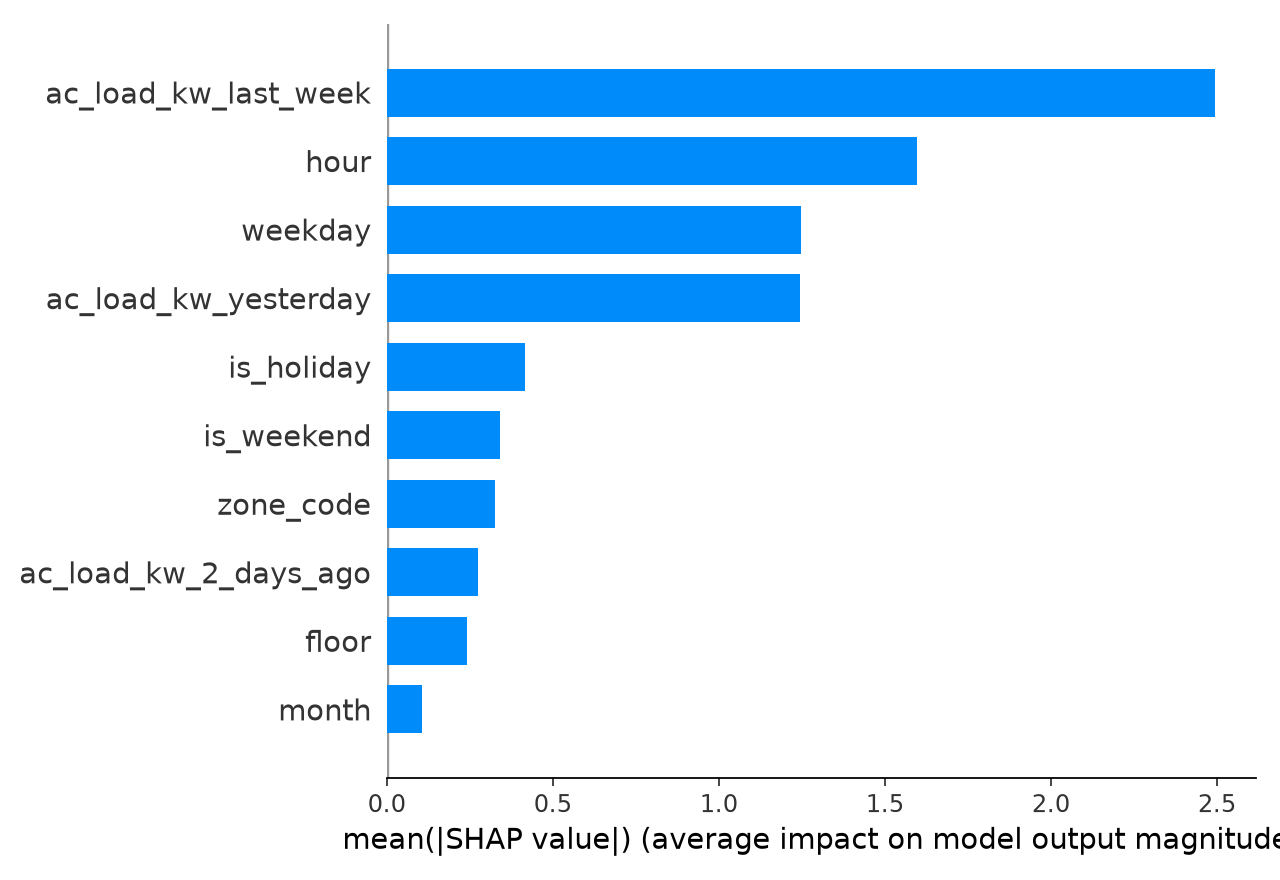

M2


,feature,gain
0,ac_load_kw_last_week,9722.853516
1,is_holiday,5528.896973
2,ac_load_kw_yesterday,1812.725098
3,is_weekend,1550.630127
4,weekday,1129.351807
5,hour,770.623413
6,indoor_temp_c_last_week,490.576477
7,ac_load_kw_2_days_ago,415.855530
8,zone_code,227.323120
9,indoor_temp_c_yesterday,201.101471


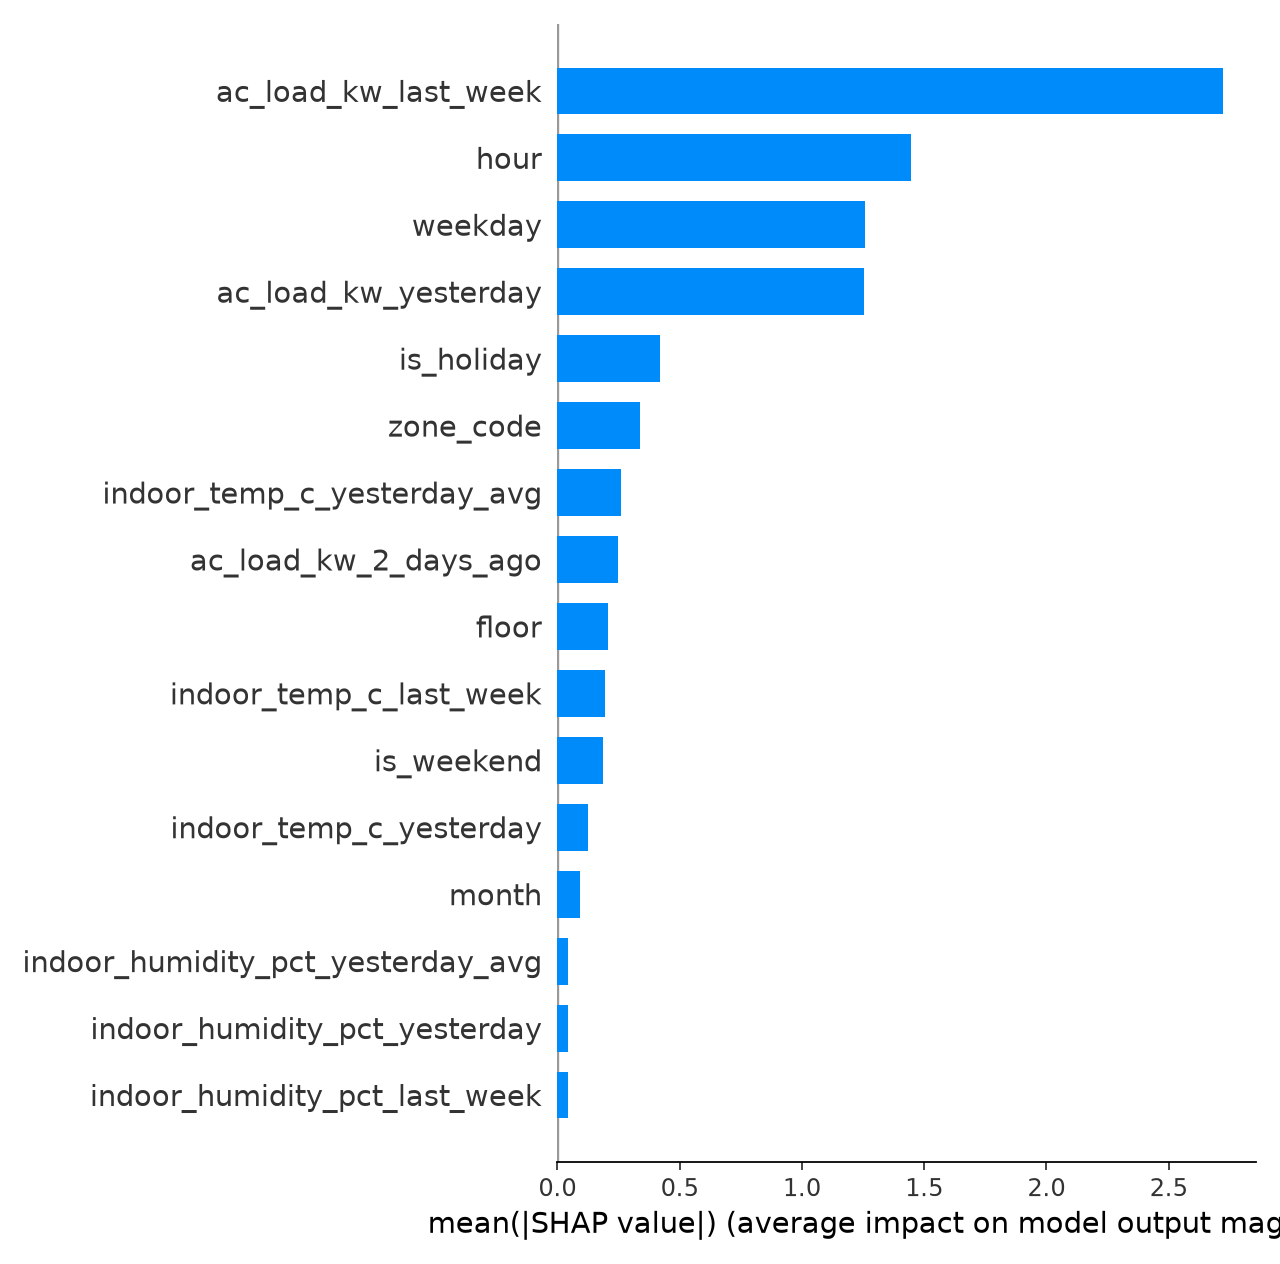

M3


,feature,gain
0,is_weekend,7513.759766
1,is_holiday,5333.488281
2,ac_load_kw_last_week,5100.794434
3,ac_load_kw_yesterday,1975.550903
4,weekday,782.226501
5,hour,572.609741
6,solar_radiation_hourly_wm2,572.038879
7,zone_code,194.336121
8,outdoor_temp_daily_avg_c,174.908585
9,rainfall_daily_total_mm,123.036430


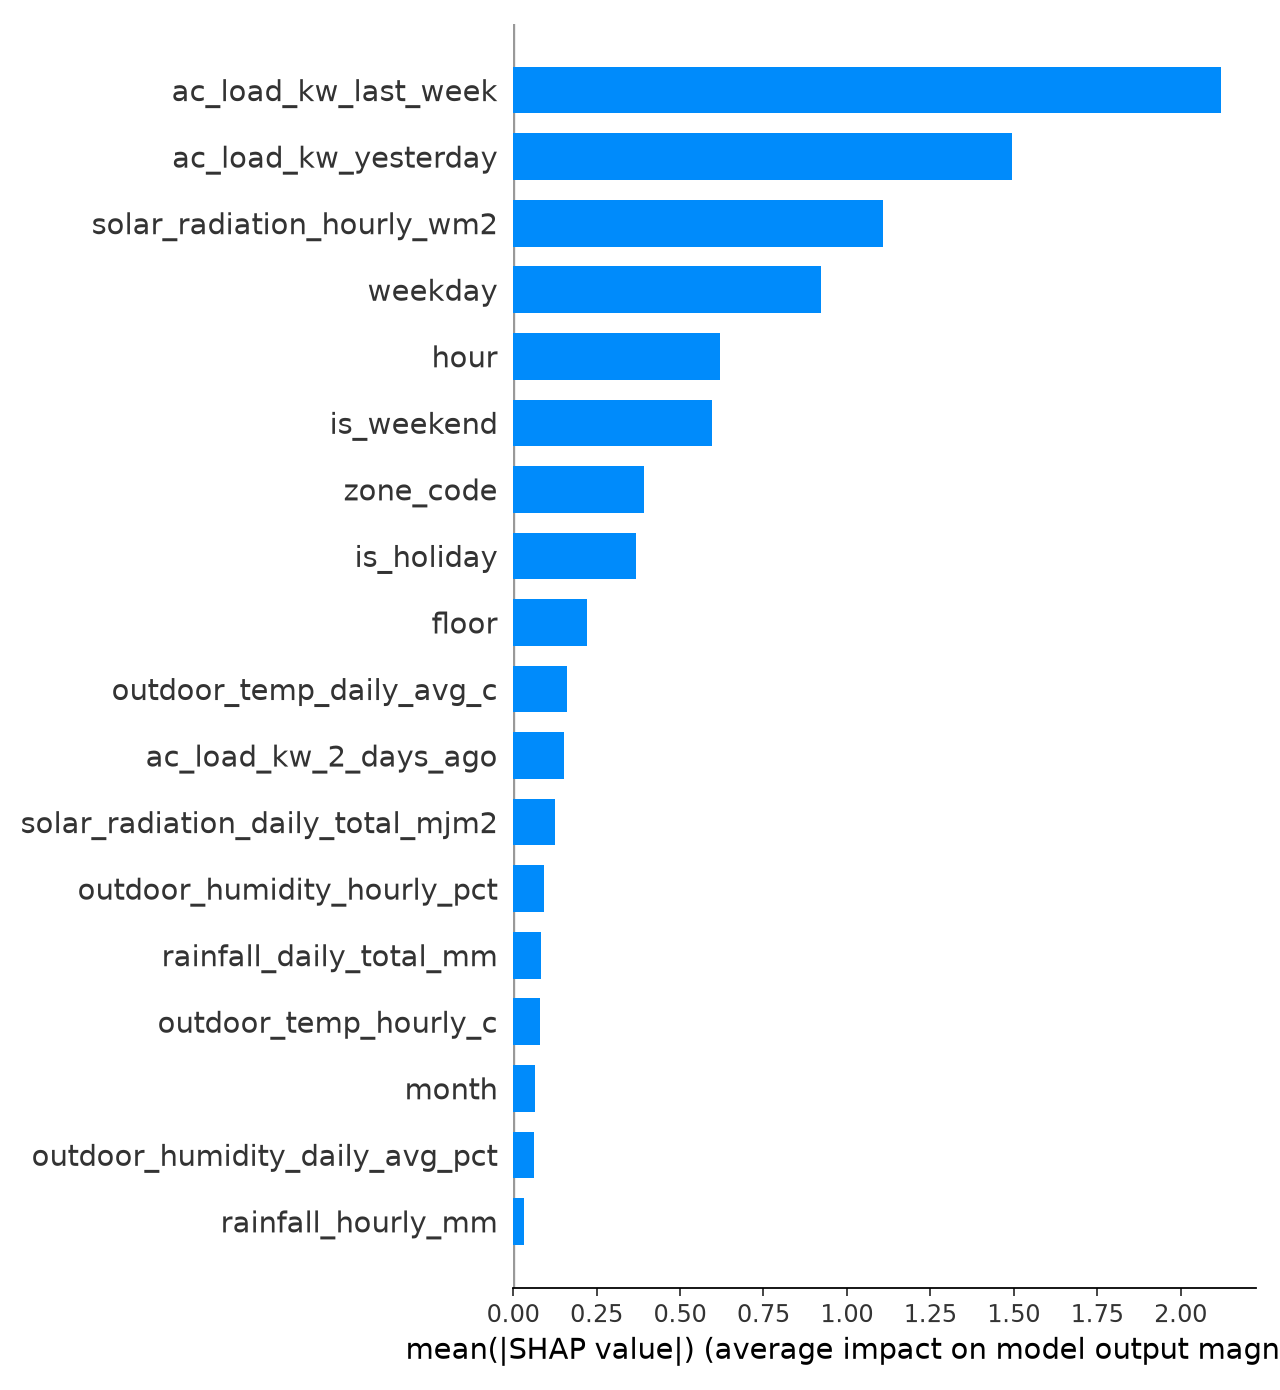

M4


,feature,gain
0,ac_load_kw_last_week,29649.072266
1,is_holiday,18319.544922
2,ac_load_kw_yesterday,6386.421387
3,weekday,4284.387695
4,is_weekend,3431.142822
5,solar_radiation_hourly_wm2,1429.443848
6,indoor_temp_c_last_week,1411.137207
7,outdoor_temp_daily_avg_c,573.928711
8,indoor_temp_c_yesterday_avg,545.163208
9,hour,481.982330


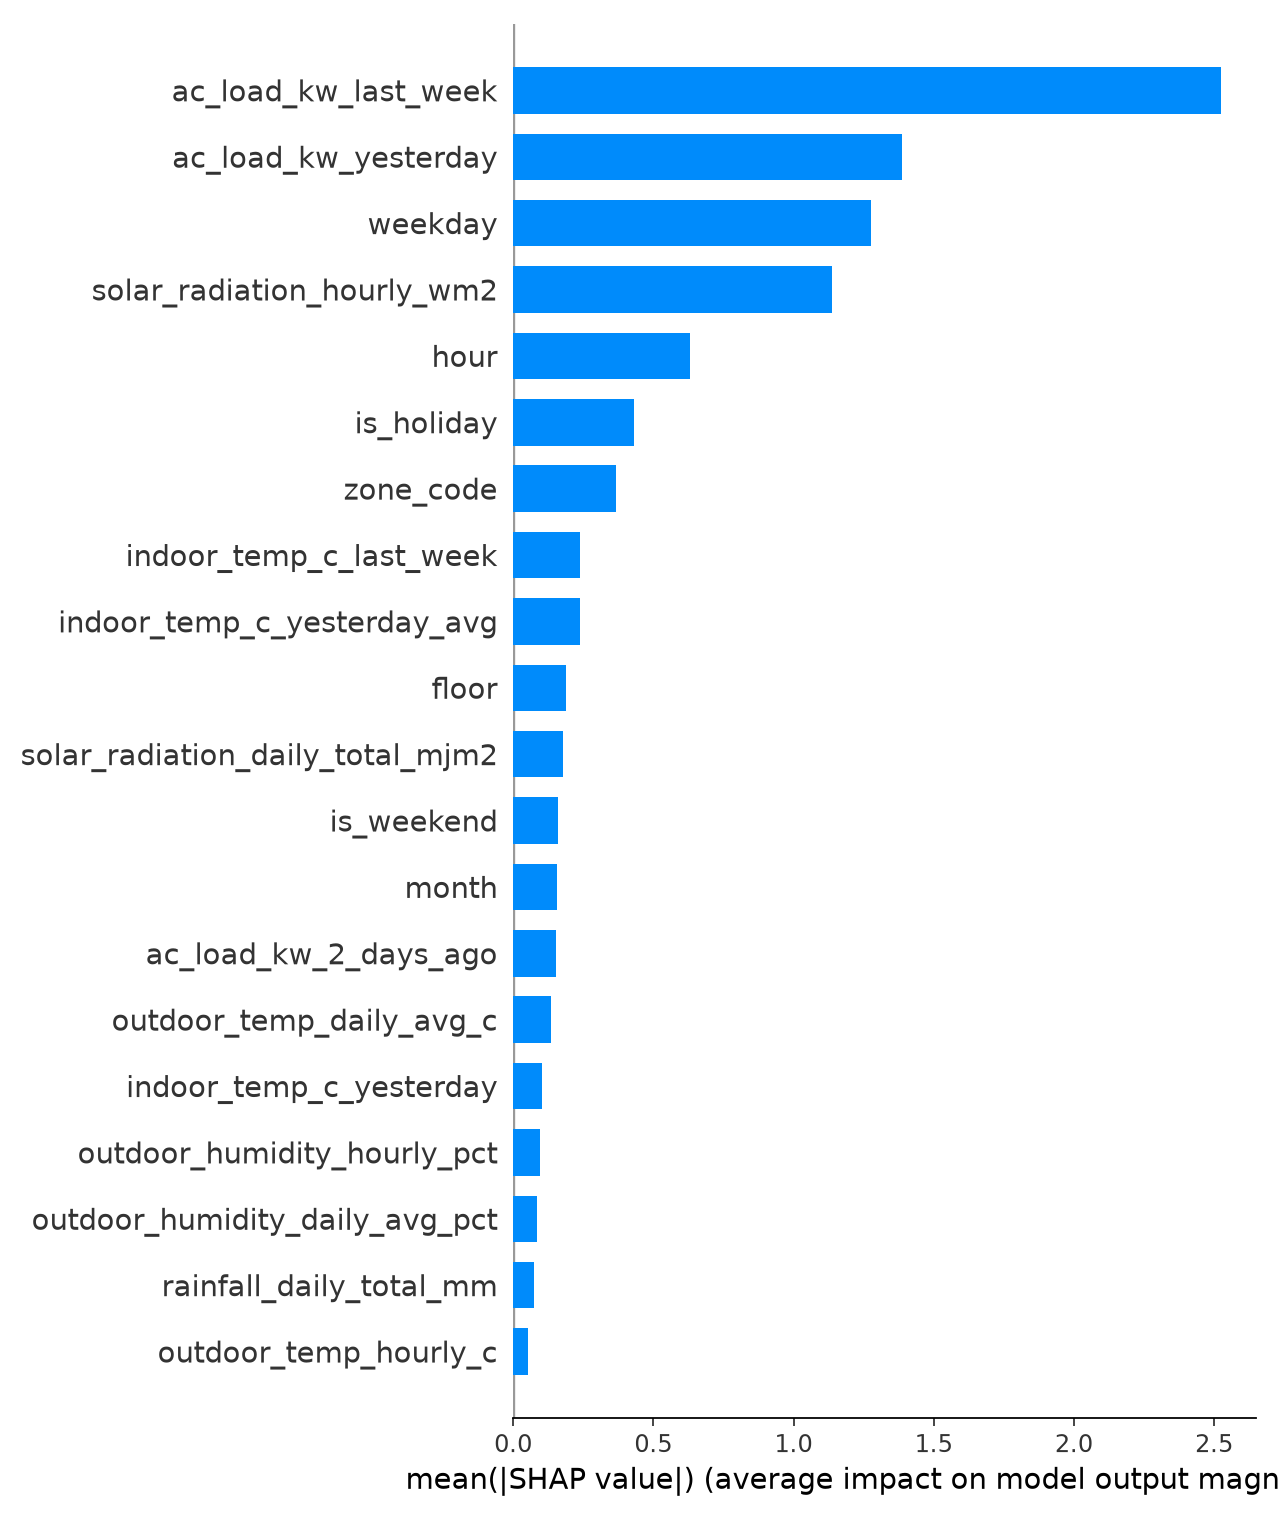

In [17]:
for model in ['M1','M2','M3','M4']:
    model_dir = OUTPUT_DIR / model
    print(model)
    display(pd.read_csv(model_dir / 'feature_importance.csv').head(10))
    display(Image(filename=str(model_dir / 'shap_bar.png'), width=650))

## 11. Dashboard prediction export

The dashboard-ready file is `outputs/test_predictions.csv`. It includes zone/timestamp identifiers, actual demand, M1–M4 predictions, operating/rain/hot-day labels, and baseline predictions where available.

In [18]:
predictions = pd.read_csv(OUTPUT_DIR / 'test_predictions.csv')
print(f'Prediction rows: {len(predictions):,}')
display(predictions.head())

Prediction rows: 50,567


,zone_id,timestamp,split,ac_load_kw,is_operating_hours,is_rainy,is_hot_day,M1_prediction,M2_prediction,M3_prediction,M4_prediction,period,split_baseline,is_operating_hours_baseline,ac_load_kw_baseline,B1 seasonal naive,B2 average profile,B3 calendar + AC lags,scored
0,F2_Z1,2018-07-01 00:00:00,test,0.0,0,0,1,1.437714,1.911705,0.021490,2.527736,test,test,0,0.0,NaN,0.361686,NaN,0
1,F2_Z1,2018-07-01 01:00:00,test,0.0,0,0,1,1.437714,1.911705,0.022165,2.527810,test,test,0,0.0,NaN,0.367054,NaN,0
2,F2_Z1,2018-07-01 02:00:00,test,0.0,0,0,1,1.437714,1.911705,0.084335,2.257859,test,test,0,0.0,NaN,0.184387,NaN,0
3,F2_Z1,2018-07-01 03:00:00,test,0.0,0,0,1,1.437714,1.911705,0.181643,2.367386,test,test,0,0.0,NaN,0.181523,NaN,0
4,F2_Z1,2018-07-01 04:00:00,test,0.0,0,0,1,1.620236,2.361433,0.190109,2.367386,test,test,0,0.0,NaN,0.178761,NaN,0
